In [69]:
import fixed_T_simulation
from fixed_T_simulation import exp_val_vs_T_diff_g
from fixed_T_simulation import plot_measurement_loop_one_observable
from matplotlib import pyplot as plt
import scipy

In [187]:
three_qubit_observables = ['IXI', 'IYI', 'IZI']

In [17]:
observables = ['IIXI', 'IIYI', 'IXII', 'IYII', 'IXXI', 'IXYI', 'IYXI', 'IYYI', 'IIII', 'IIZI', 'IZII', 'IZZI']

In [137]:
def exp_val_vs_T_diff_g(n=3, observable="IXI", save_fig=False, gs=[0.25, 0.5, 0.75, 1.0, 1.25, 1.5]):
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = plt.cm.Blues(np.linspace(0, 1, len(gs)+1))[1:]
    
    for g, color in zip(gs,colors):
        T_vals = []
        for t in range(0, 15): 
            T_vals.extend(np.linspace(t, t+1, 10+1))
        exp_vals = []
        for T in T_vals:
            val = plot_measurement_loop_one_observable(n, 10, observable, T, g)[1][0]
            exp_vals.append(val)

        ax.plot(T_vals, exp_vals, "o-", markersize=4, label=f"g={g}, Δt={1.0/10}", color=color)

    ax.set_xlabel("Total time T")
    ax.set_ylabel(f"{observable} Expectation Value")
    ax.set_title(f"Expectation vs T, for g = {g}")
    ax.grid(True)
    ax.legend(title="Steps N")

    fig.tight_layout()
    if save_fig:
        fig.savefig(f"{observable}_vs_T_steps.png")
    plt.show()

In [203]:
def plot_fft_diff_g(n=3, observable="IXI", save_fig=False, gs=[0.25, 0.5, 0.75, 1.0, 1.25, 1.5]):
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = plt.cm.Blues(np.linspace(0, 1, len(gs)+1))[1:]
    
    for g, color in zip(gs,colors):
        T_vals = []
        for t in range(0, 15): 
            T_vals.extend(np.linspace(t, t+1, 10+1)[:-1])
        T_vals.append(15.0)
        # exp_vals = []
        # for T in T_vals:
        #     val = plot_measurement_loop_one_observable(n, 10, observable, T, g)[1][0]
        #     exp_vals.append(val)
        exp_vals = [plot_measurement_loop_one_observable(n, 10, observable, T, g)[1][0] for T in T_vals]

        dt = T_vals[1] - T_vals[0]
        yf  = np.fft.rfft(exp_vals)
        xf  = np.fft.rfftfreq(len(exp_vals), dt)
        ax.plot(xf, np.abs(yf), label=f"g={g}", color = color)

    ax.set_xlabel("Frequency (cycles per T)")
    ax.set_ylabel("|FFT|")
    ax.set_title(f"FFT of {observable} for multiple g")
    ax.set_xlim(-0.3, 5)
    ax.grid(True)
    ax.legend(title="Steps N")
    fig.tight_layout()
    plt.show()

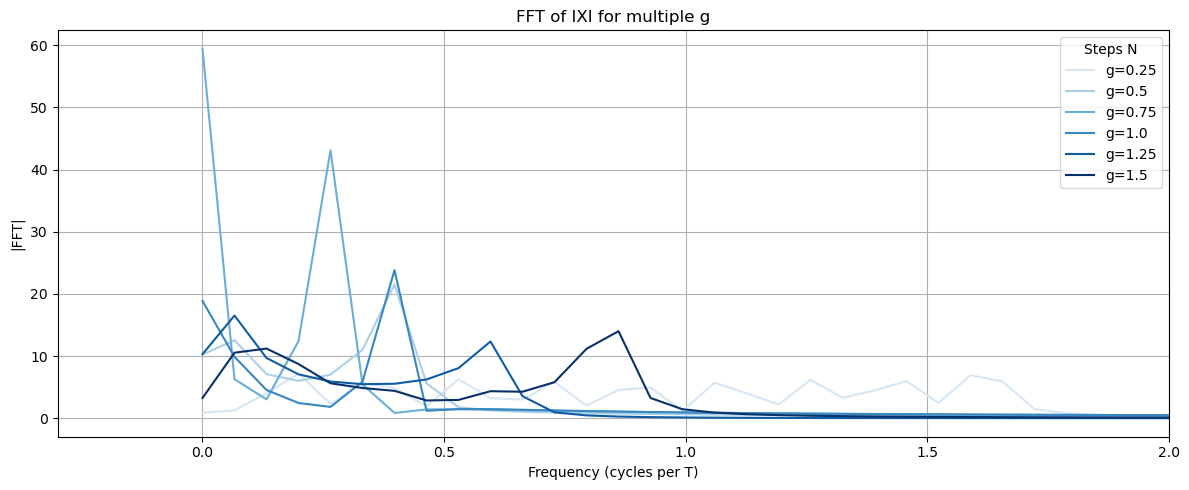

In [183]:
plot_fft_diff_g()

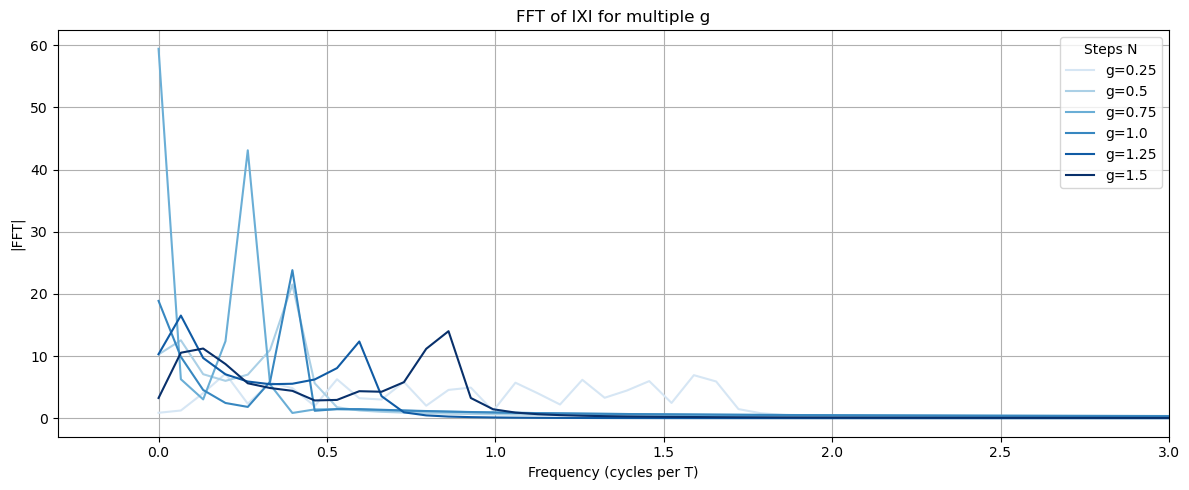

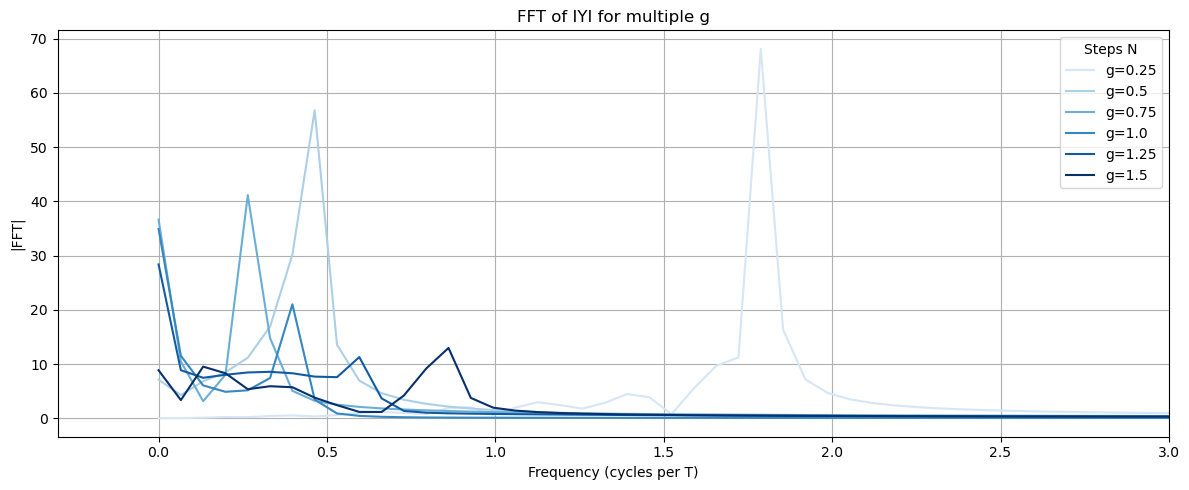

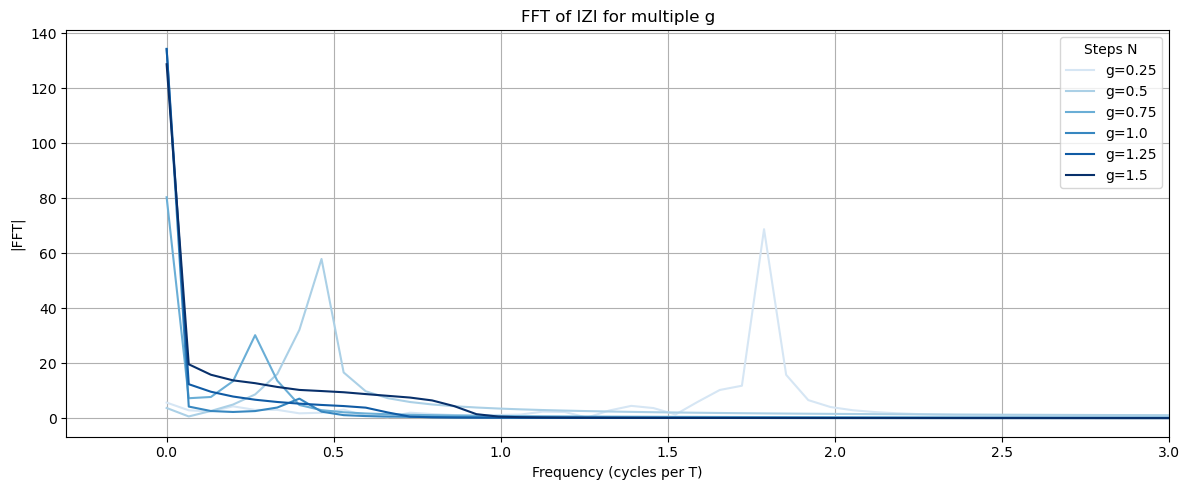

In [197]:
for observable in three_qubit_observables:
    plot_fft_diff_g(3, observable)

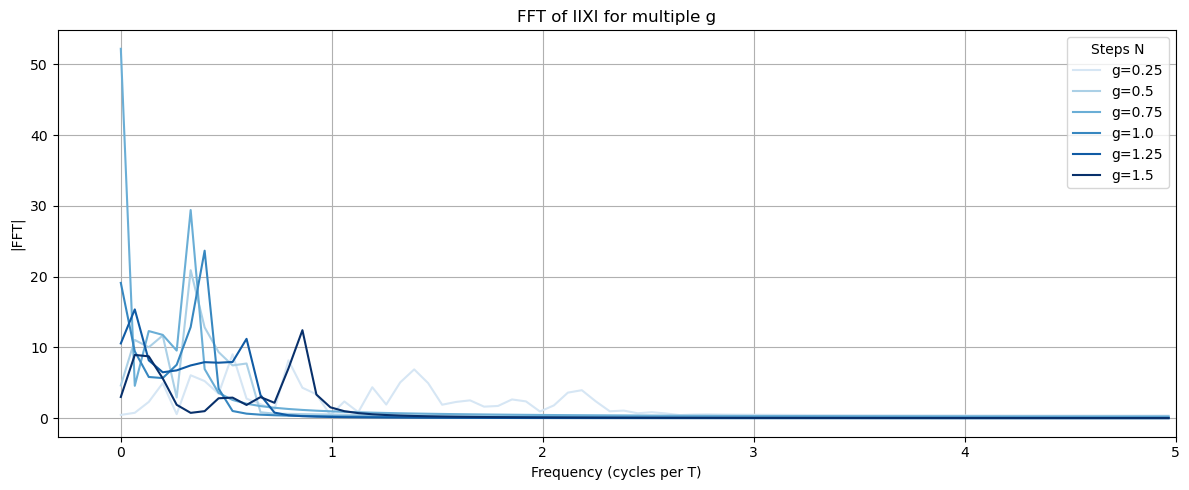

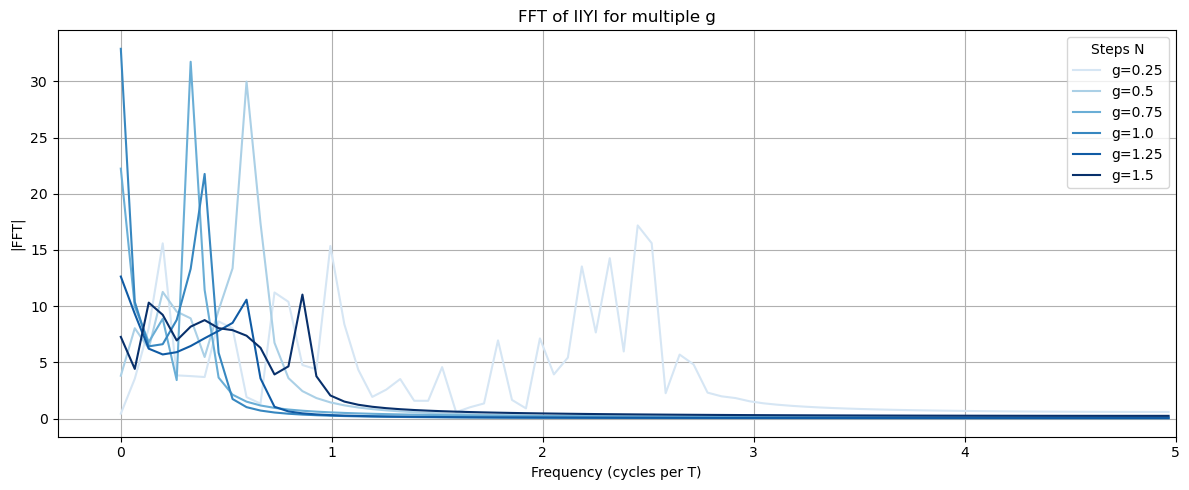

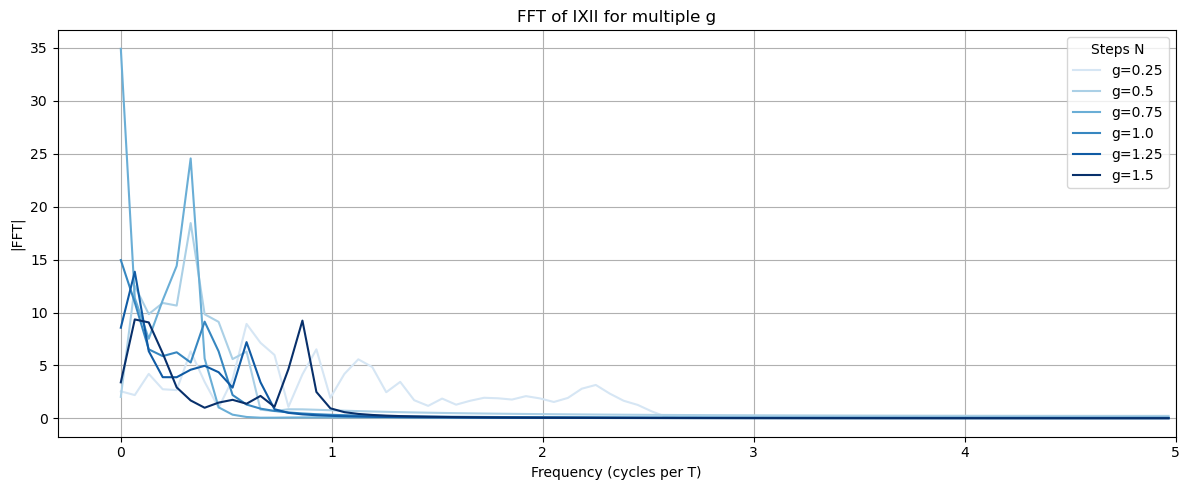

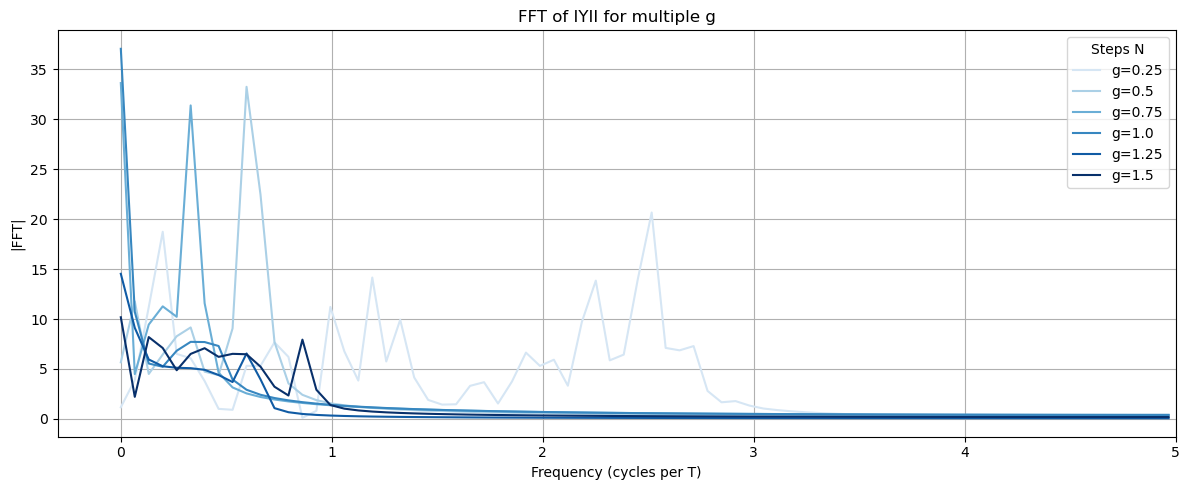

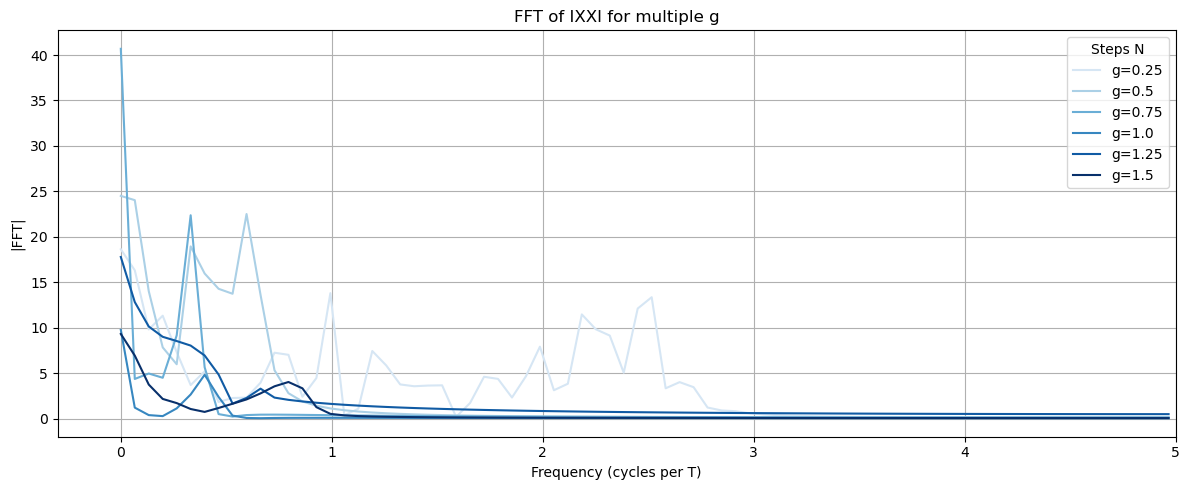

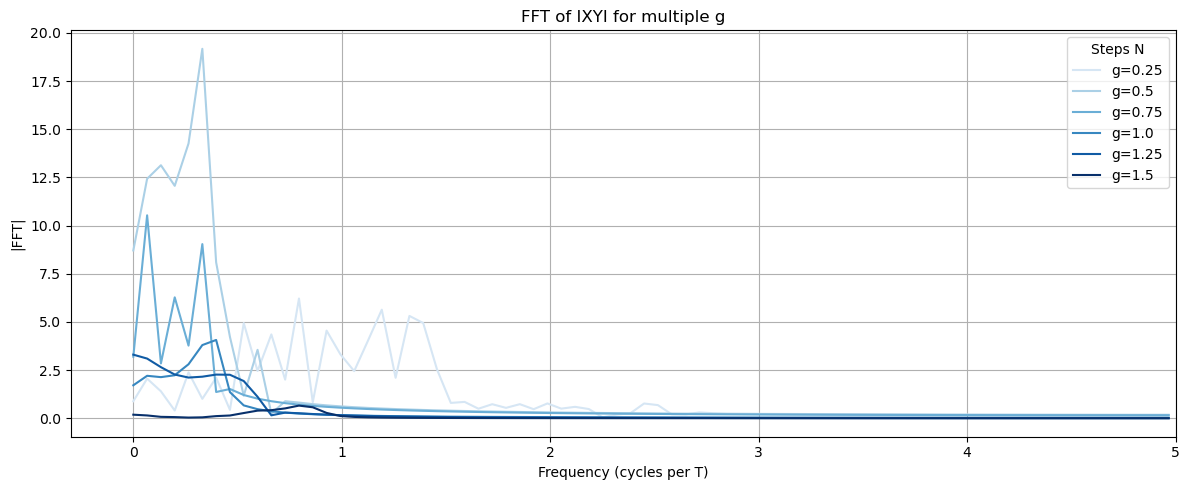

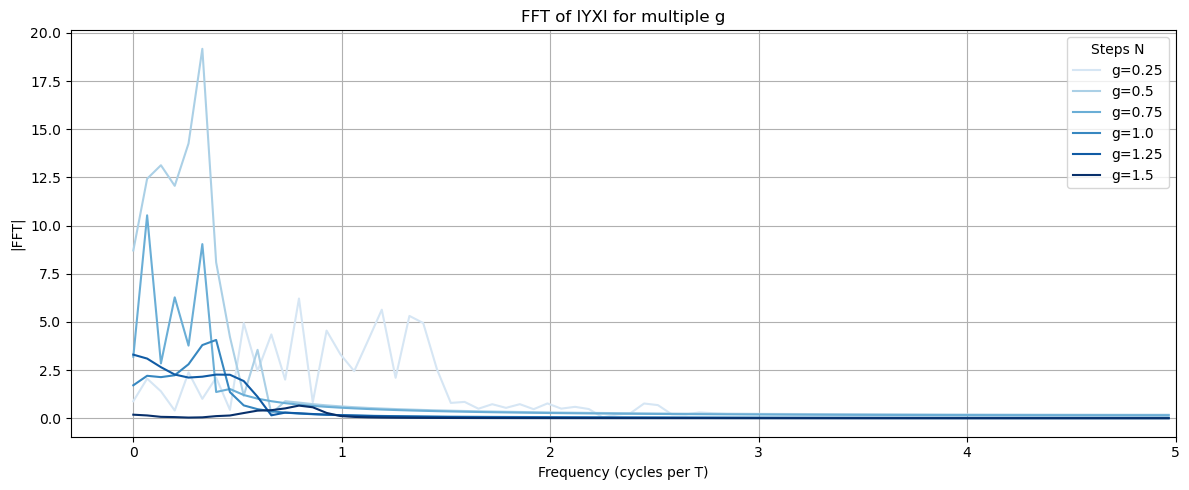

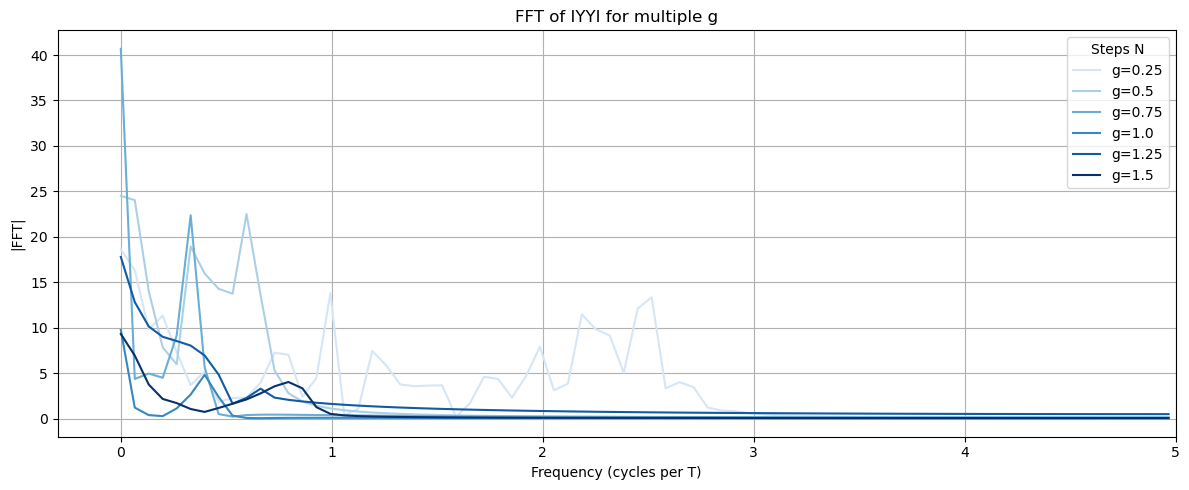

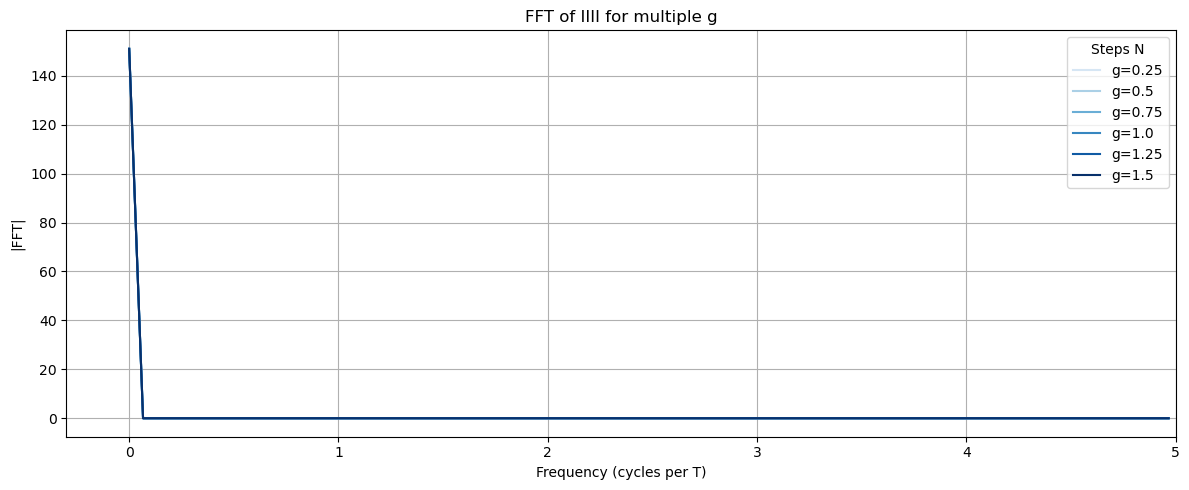

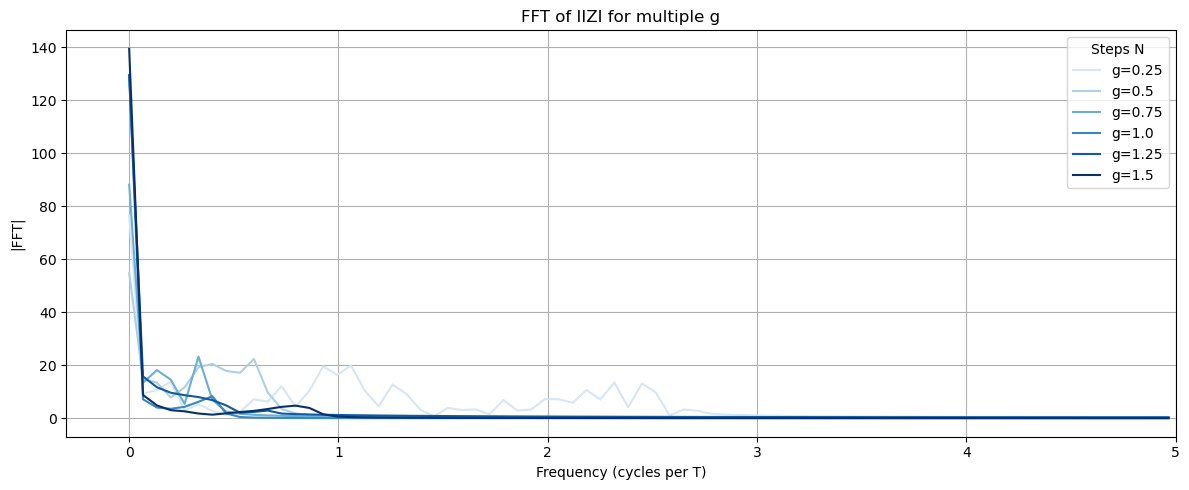

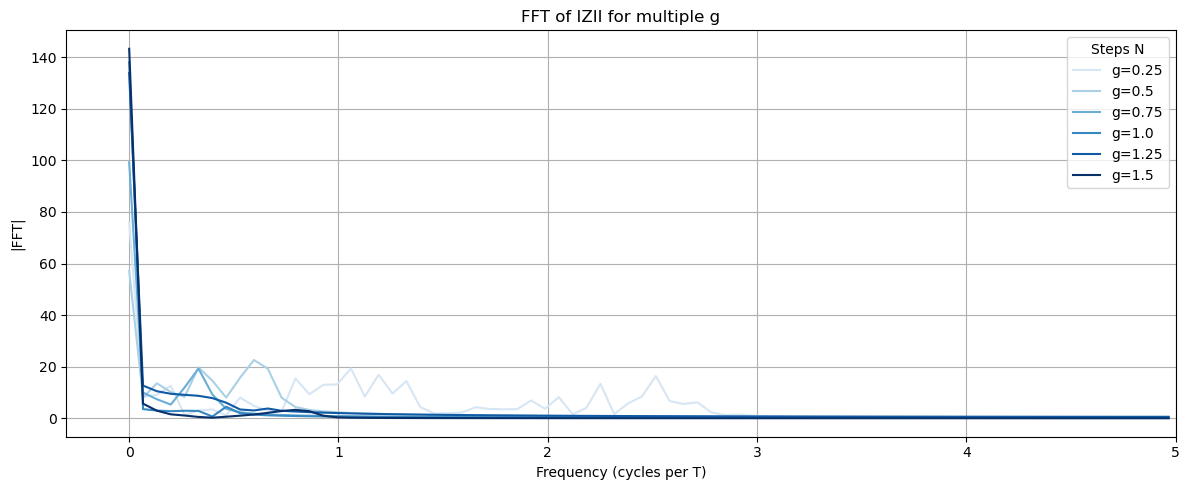

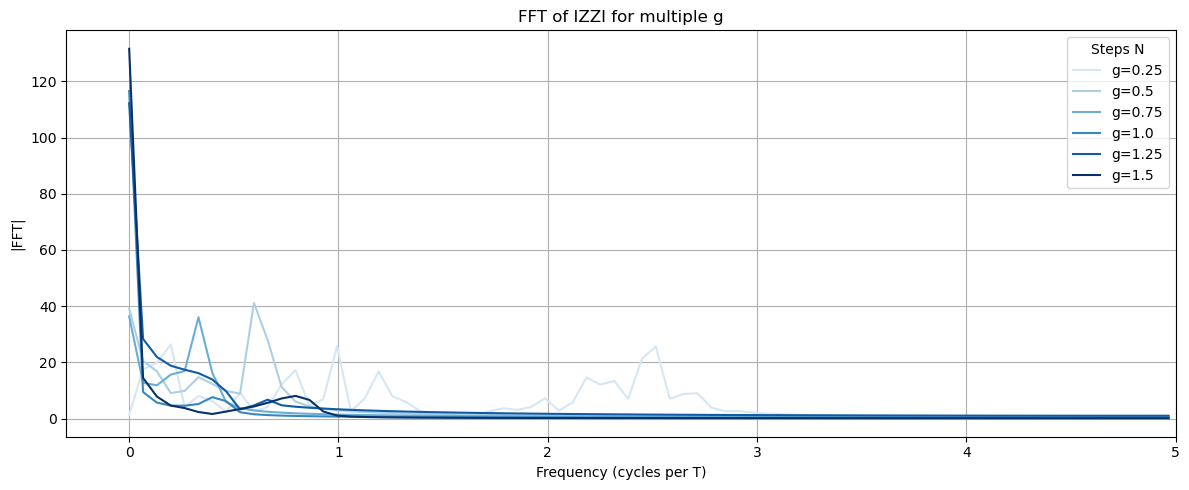

In [201]:
for observable in observables:
    plot_fft_diff_g(4, observable)